# E-Commerce Customer Segmentation: An End-to-End Machine Learning Deep-Dive
**Author:** Principal Machine Learning & Data Science Specialist  
**Methodology:** Transaction Preprocessing $\rightarrow$ RFM Feature Engineering $\rightarrow$ Log Transformation & Standardization $\rightarrow$ K-Means & DBSCAN $\rightarrow$ PCA & t-SNE Manifold Learning $\rightarrow$ Actionable Marketing Personas  
**Dataset:** Online Retail E-Commerce Database (`orders.csv` & `customers.csv`)

---

## Executive Abstract & Problem Formulation
In modern digital commerce, treating customers as a homogeneous population leads to severe marketing inefficiencies, high churn rates, and depressed customer lifetime value (LTV). A blanket 20% discount coupon sent to your entire database subsidizes purchases for loyal customers who would have bought anyway, while alienating high-intent or dormant customers who require different psychological and financial triggers.

### The Machine Learning Mission
We formulate customer segmentation as an **Unsupervised Learning** problem to uncover latent behavioural archetypes from transactional telemetry. The pipeline follows a rigorous, production-grade progression:
1. **Transaction Telemetry Cleansing:** Isolate retained revenue from refunded/cancelled transactions and establish a calendar snapshot anchor.
2. **Behavioral Feature Engineering (RFM):** Synthesize event-stream transactions into customer-level Recency ($R$), Frequency ($F$), and Monetary ($M$) vectors.
3. **Distribution Diagnostics & Transformation:** Diagnose heavy right-tail power laws, apply variance-stabilizing monotonic log transformations ($\ln(1+x)$), and standardize feature scales ($z$-score scaling).
4. **Partitioning Clustering (K-Means):** Formulate the Within-Cluster Sum of Squares (Inertia) objective, optimize $K$ via joint Elbow analysis and Silhouette coefficient decomposition, and inspect cluster convergence.
5. **Density-Based Spatial Clustering (DBSCAN):** Construct the $k$-distance graph to locate the empirical knee for $\epsilon$, isolate core vs border points, and extract anomalous purchasing patterns and noise ($-1$).
6. **Dimensionality Reduction & Manifold Projection:**
   - **PCA (Linear):** Diagonalize the feature covariance matrix, compute explained variance ratios, and interpret component loadings.
   - **t-SNE (Non-Linear):** Minimize Kullback-Leibler divergence with Student-$t$ kernels to project local neighbourhood manifolds into 2D space.
7. **Persona Extraction & Commercial Strategy:** Translate geometric centroids into commercial personas (**Champions**, **At-Risk High-Spenders**, **Recent Occasional Buyers**, **Hibernating Customers**), validate the Pareto Principle ($80/20$ rule), and synthesize cross-channel marketing playbooks.


## Step 1: Environment Setup & Reproducibility Configuration

### Machine Learning Thinker's Note:
Reproducibility is paramount in unsupervised learning. Distance-based algorithms like K-Means rely on random centroid initializations (even with K-Means++), and non-linear manifold embeddings like t-SNE depend on stochastic gradient descent over probabilistic neighborhoods. Setting strict random seeds (`random_state=42`) guarantees consistent cluster assignments across experiment runs and production pipelines.


In [1]:
# Standard Data Science & Numeric Stack
import pandas as pd
import numpy as np
import scipy.stats as stats

# Visualization Stack
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Machine Learning Stack
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Configure Plot Styling & High-DPI Rendering
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Environment successfully initialized. Random seed locked to 42.")


Environment successfully initialized. Random seed locked to 42.


## Step 2: Data Ingestion & Transactional Telemetry Preprocessing

### Mathematical & Domain Considerations:
1. **Order Telemetry vs Customer Entities:** Raw e-commerce databases log individual purchase transactions. A customer placing 10 orders has 10 records. Unsupervised customer clustering requires **one vector per customer entity** ($\mathbf{x}_i \in \mathbb{R}^d$).
2. **Refunds and Cancellations:** Retail datasets contain failed, refunded, or cancelled orders. If an order is refunded, the gross transaction amount was reversed. Retaining refunded transactions would distort both Monetary spend and Frequency metrics. We strictly filter for `status == 'completed'`.
3. **Timestamp Standardization:** Date strings must be parsed into ISO datetime objects to enable calendar arithmetic.


In [2]:
# Ingest Raw Transactional Orders and Customer Demographics
orders_df = pd.read_csv('dataset/rfm-analysis-customers-and-orders-for-e-commerce-segmentation-v1-csv-orders.csv')
customers_df = pd.read_csv('dataset/rfm-analysis-customers-and-orders-for-e-commerce-segmentation-v1-csv-customers.csv')

print(f"Raw Orders Record Count: {len(orders_df)}")
print(f"Registered Customers Count: {len(customers_df)}")
print("\n--- Transaction Status Distribution ---")
print(orders_df['status'].value_counts())

# Filter for Completed Transactions Only
clean_orders = orders_df[orders_df['status'] == 'completed'].copy()

# Parse Datetime Fields
clean_orders['ordered_at'] = pd.to_datetime(clean_orders['ordered_at'])

print(f"\nRetained Completed Orders: {len(clean_orders)} ({len(clean_orders)/len(orders_df)*100:.1f}%)")
print(f"Active Transaction Date Horizon: {clean_orders['ordered_at'].min().strftime('%Y-%m-%d')} to {clean_orders['ordered_at'].max().strftime('%Y-%m-%d')}")
display(clean_orders.head(3))


Raw Orders Record Count: 818
Registered Customers Count: 220

--- Transaction Status Distribution ---
status
completed    780
refunded      38
Name: count, dtype: int64

Retained Completed Orders: 780 (95.4%)
Active Transaction Date Horizon: 2022-01-29 to 2024-12-24


,id,customer_id,order_number,ordered_at,items,order_total,channel,status
0,1,140,R-79274213,2023-10-18 15:06:26,1,17.00,web,completed
1,2,157,R-37757181,2024-01-13 20:26:39,1,64.56,web,completed
2,3,48,R-07037372,2023-06-07 15:54:10,1,95.47,web,completed


## Step 3: RFM Feature Engineering

The **RFM framework** aggregates transactional logs into three foundational behavioral signals:
1. **Recency ($R$):** Days elapsed since the customer's most recent completed order relative to a snapshot anchor date ($t_{\text{ref}}$).
   $$R_i = t_{\text{ref}} - \max_{j \in \mathcal{O}_i} (t_{i,j})$$
   *Interpretation:* Lower recency indicates higher temporal engagement. A customer who purchased yesterday is dramatically more receptive to retention offers than one who purchased two years ago.
2. **Frequency ($F$):** Total count of unique completed purchase events.
   $$F_i = |\mathcal{O}_i|$$
   *Interpretation:* Higher frequency reflects habitual engagement and brand loyalty.
3. **Monetary ($M$):** Cumulative monetary revenue generated by customer $i$.
   $$M_i = \sum_{j \in \mathcal{O}_i} \text{order\_total}_{i,j}$$
   *Interpretation:* Higher monetary value directly quantifies customer financial contribution.

### Snapshot Reference Anchor ($t_{\text{ref}}$):
In historical dataset analysis, setting $t_{\text{ref}}$ to today's date would artificially inflate recency by years. Standard practice sets $t_{\text{ref}} = \max(t_{\text{order}}) + 1\text{ day}$, representing the day after the last transaction recorded in the database.


In [3]:
# Establish Temporal Anchor (1 day after final observed transaction)
snapshot_date = clean_orders['ordered_at'].max() + pd.Timedelta(days=1)
print(f"Calculated Snapshot Anchor Date: {snapshot_date}")

# Group by customer_id and compute RFM metrics
rfm_raw = clean_orders.groupby('customer_id').agg(
    Recency=('ordered_at', lambda x: (snapshot_date - x.max()).days),
    Frequency=('order_number', 'nunique'),
    Monetary=('order_total', 'sum')
).reset_index()

print(f"Total Unique Transacting Customers: {len(rfm_raw)}")
print("\n--- Parametric RFM Summary Statistics ---")
display(rfm_raw.describe().round(2))


Calculated Snapshot Anchor Date: 2024-12-25 20:41:17
Total Unique Transacting Customers: 216

--- Parametric RFM Summary Statistics ---


,customer_id,Recency,Frequency,Monetary
count,216.00,216.00,216.00,216.00
mean,111.55,437.62,3.61,208.63
std,63.49,265.12,3.23,291.78
min,1.00,1.00,1.00,6.07
25%,57.75,213.00,1.00,28.57
50%,111.50,409.50,2.00,79.02
75%,166.25,633.50,6.00,313.00
max,220.00,1061.00,12.00,1653.67


## Step 4: Statistical Distribution Diagnostics & Preprocessing

### Machine Learning Thinker's Diagnostic:
E-commerce transactional metrics almost never follow Gaussian normal distributions. Instead, they exhibit **heavy right tails and power-law dynamics (Pareto distribution)**:
- Most customers buy 1 or 2 times and spend modest amounts.
- A small cohort of "whales" places 15+ orders and spends thousands of dollars.

### Why Standard Preprocessing Fails Without Transformation:
1. **Euclidean Distance Distortion:** Distance-based algorithms (K-Means, DBSCAN) rely on $\ell_2$ distance:
   $$d(\mathbf{u}, \mathbf{v}) = \sqrt{(R_u - R_v)^2 + (F_u - F_v)^2 + (M_u - M_v)^2}$$
   If unscaled, Monetary values ($M \in [10, 2000]$) overpower Frequency ($F \in [1, 10]$) by three orders of magnitude. The algorithm degenerates into a 1D spend clustering.
2. **The Role of Log Transformation (`np.log1p`):**
   $$y = \ln(1 + x)$$
   The log transform compresses exponential tails, symmetrizes the distribution, and stabilizes feature variance without altering the rank order of customers.
3. **Standardization (`StandardScaler`):**
   $$z = \frac{x - \mu}{\sigma}$$
   Brings all features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$), ensuring equal weighting across geometric dimensions.


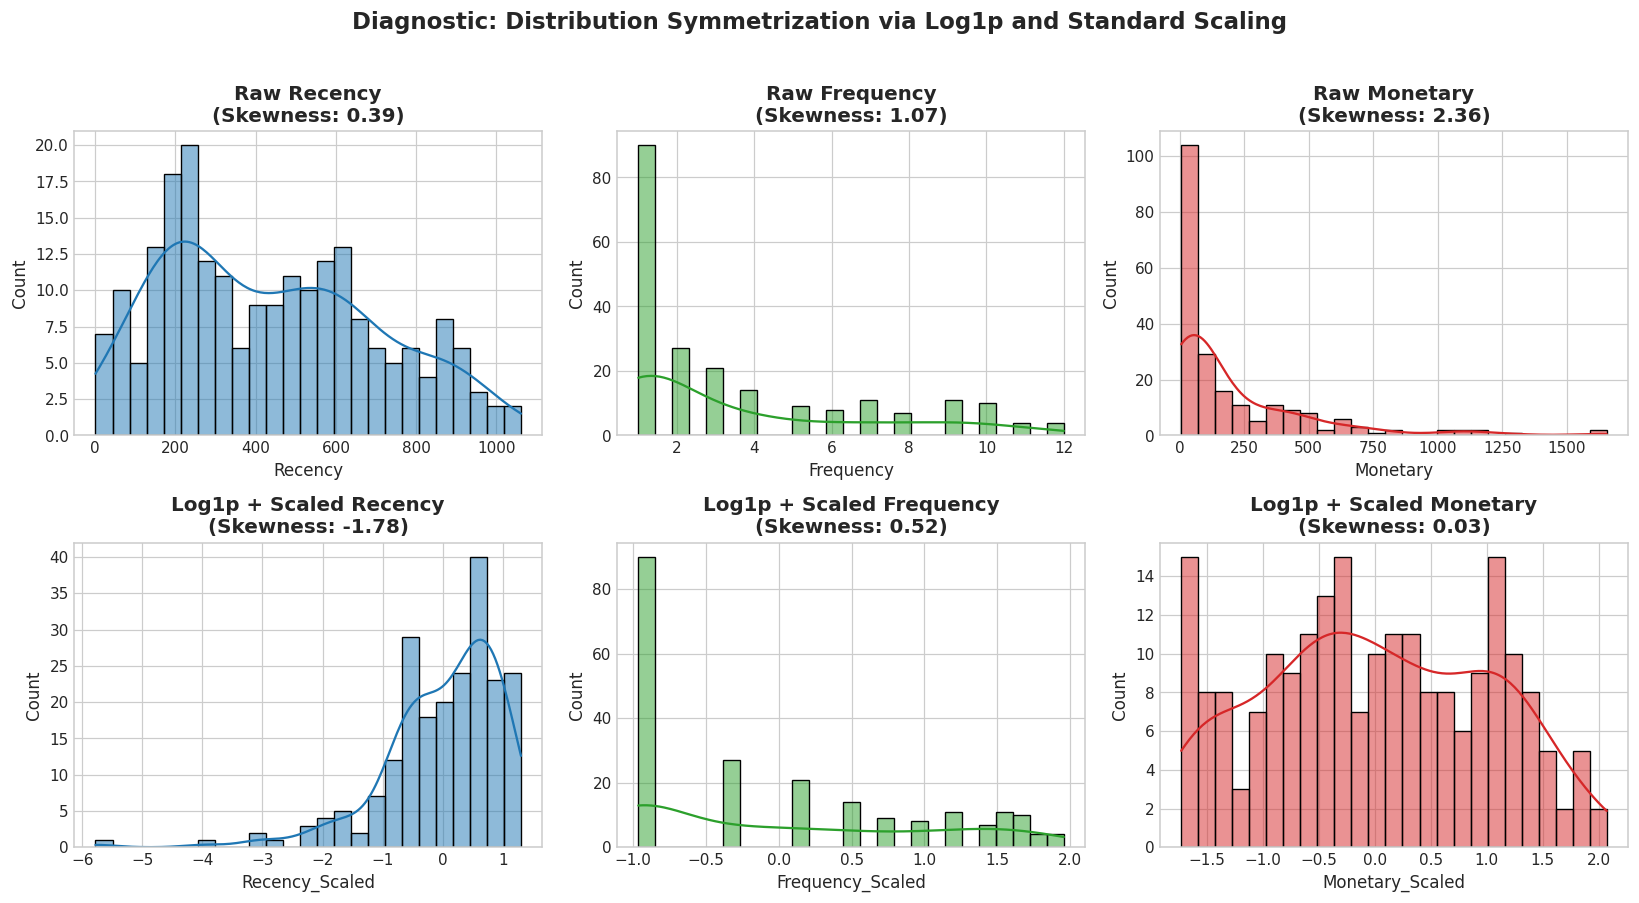

Feature Skewness Comparison:
           Raw Skewness  Log1p Skewness
Recency            0.39           -1.78
Frequency          1.07            0.52
Monetary           2.36            0.03


In [4]:
# Compute Skewness Before Transformation
raw_skew = rfm_raw[['Recency', 'Frequency', 'Monetary']].apply(lambda x: stats.skew(x)).round(2)

# Apply Log Transformation: ln(1 + x)
rfm_log = np.log1p(rfm_raw[['Recency', 'Frequency', 'Monetary']])
log_skew = rfm_log.apply(lambda x: stats.skew(x)).round(2)

# Apply Standardization
scaler = StandardScaler()
rfm_scaled_array = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled_array, columns=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'])

# Visual Diagnostic: Before vs After Transformation
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
colors = ['#1f77b4', '#2ca02c', '#d62728']

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    # Raw distribution
    sns.histplot(rfm_raw[col], kde=True, ax=axes[0, i], color=colors[i], bins=25)
    axes[0, i].set_title(f'Raw {col}\n(Skewness: {raw_skew[col]})', fontweight='bold')
    
    # Log-transformed & Scaled distribution
    sns.histplot(rfm_scaled.iloc[:, i], kde=True, ax=axes[1, i], color=colors[i], bins=25)
    axes[1, i].set_title(f'Log1p + Scaled {col}\n(Skewness: {log_skew[col]})', fontweight='bold')

plt.suptitle('Diagnostic: Distribution Symmetrization via Log1p and Standard Scaling', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Feature Skewness Comparison:")
print(pd.DataFrame({'Raw Skewness': raw_skew, 'Log1p Skewness': log_skew}))


## Step 5: K-Means Clustering — Optimization, Diagnostics & Model Fitting

### Algorithmic Mechanics:
K-Means partitions $n$ observations into $K$ disjoint clusters $\mathcal{C} = \{C_1, C_2, \dots, C_K\}$ by minimizing the **Within-Cluster Sum of Squares (WCSS / Inertia)**:
$$\mathcal{J} = \sum_{k=1}^K \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2$$
where $\boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i$ is the geometric centroid.

### Scientific Determination of Optimal $K$:
A disciplined ML practitioner never relies on the Elbow heuristic in isolation. We utilize a dual validation framework:
1. **The Elbow Method:** Measures the second derivative of WCSS with respect to $K$. As $K$ increases, WCSS monotonically decreases; the "elbow" is the point of inflection where diminishing marginal returns occur.
2. **Silhouette Analysis:** Measures how well-separated cluster boundaries are. For sample $i$:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   - $a(i)$: Mean intra-cluster distance between sample $i$ and all other points in its assigned cluster.
   - $b(i)$: Mean nearest-cluster distance between sample $i$ and the closest neighboring cluster.
   - $s(i) \in [-1, +1]$: Values near $+1$ indicate tight cohesion and large separation; values near $0$ indicate overlapping boundaries; negative values indicate misclassification.
3. **Information Criteria / Unsupervised Metrics:** Davies-Bouldin Index (lower is better) and Calinski-Harabasz Index (higher is better).


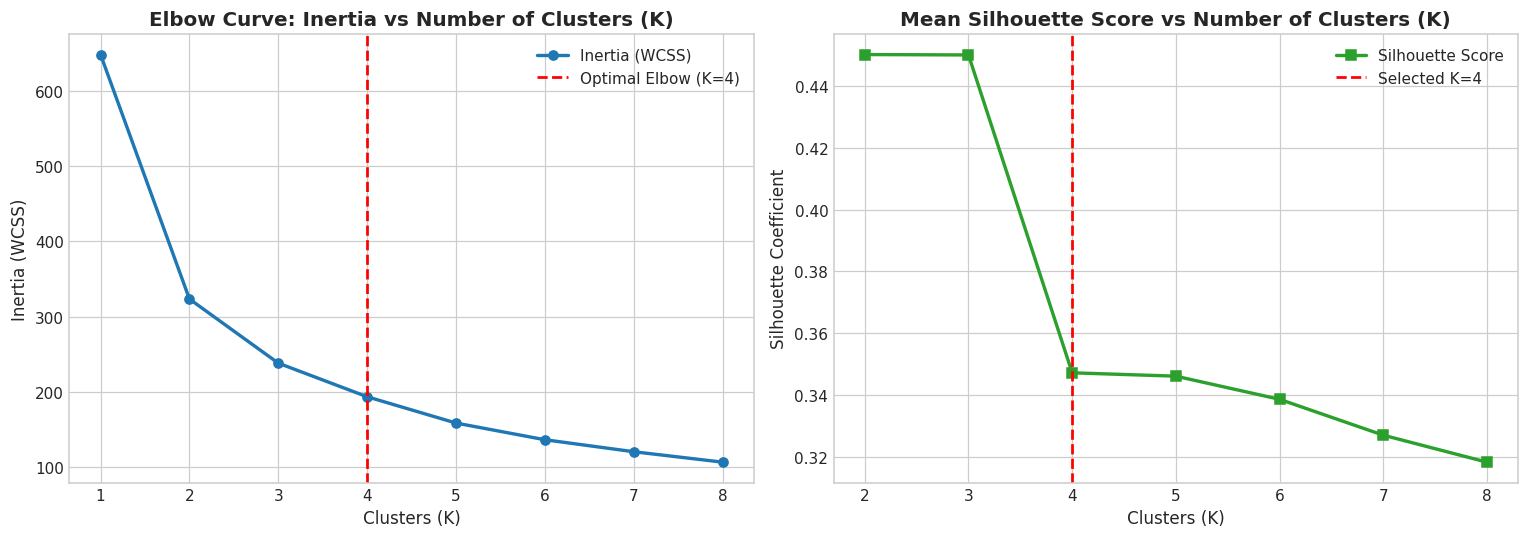

=== Unsupervised Cluster Validation Metrics ===


,K,Silhouette Score (Higher Better),Davies-Bouldin Index (Lower Better),Calinski-Harabasz Index (Higher Better)
0,2,0.450,0.895,214.8
1,3,0.450,0.861,183.2
2,4,0.347,1.036,165.9
3,5,0.346,1.008,162.7
4,6,0.339,0.975,157.4
5,7,0.327,0.945,152.4
6,8,0.318,0.974,150.7


In [5]:
# Evaluate K over range [2, 8]
k_candidates = list(range(2, 9))
wcss_values = []
silhouette_values = []
db_scores = []
ch_scores = []

# Also compute K=1 for Elbow WCSS
km1 = KMeans(n_clusters=1, random_state=42, n_init=10)
km1.fit(rfm_scaled_array)
wcss_all = [km1.inertia_]

for k in k_candidates:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled_array)
    wcss_all.append(km.inertia_)
    silhouette_values.append(silhouette_score(rfm_scaled_array, labels))
    db_scores.append(davies_bouldin_score(rfm_scaled_array, labels))
    ch_scores.append(calinski_harabasz_score(rfm_scaled_array, labels))

# Plot Elbow and Silhouette Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Elbow Curve
axes[0].plot(range(1, 9), wcss_all, marker='o', linewidth=2.2, color='#1f77b4', label='Inertia (WCSS)')
axes[0].axvline(x=4, color='red', linestyle='--', linewidth=1.8, label='Optimal Elbow (K=4)')
axes[0].set_title('Elbow Curve: Inertia vs Number of Clusters (K)', fontweight='bold')
axes[0].set_xlabel('Clusters (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].legend()

# Plot 2: Silhouette Scores
axes[1].plot(k_candidates, silhouette_values, marker='s', linewidth=2.2, color='#2ca02c', label='Silhouette Score')
axes[1].axvline(x=4, color='red', linestyle='--', linewidth=1.8, label='Selected K=4')
axes[1].set_title('Mean Silhouette Score vs Number of Clusters (K)', fontweight='bold')
axes[1].set_xlabel('Clusters (K)')
axes[1].set_ylabel('Silhouette Coefficient')
axes[1].legend()

plt.tight_layout()
plt.show()

# Tabular validation summary
metrics_df = pd.DataFrame({
    'K': k_candidates,
    'Silhouette Score (Higher Better)': np.round(silhouette_values, 3),
    'Davies-Bouldin Index (Lower Better)': np.round(db_scores, 3),
    'Calinski-Harabasz Index (Higher Better)': np.round(ch_scores, 1)
})
print("=== Unsupervised Cluster Validation Metrics ===")
display(metrics_df)


### Deep-Dive: Silhouette Analysis per Cluster for $K=4$
The aggregate silhouette score can hide internal cluster pathology (e.g., one huge dense cluster skewing the average while another cluster contains misclassified samples with negative scores). We plot the per-sample silhouette thickness and boundaries.


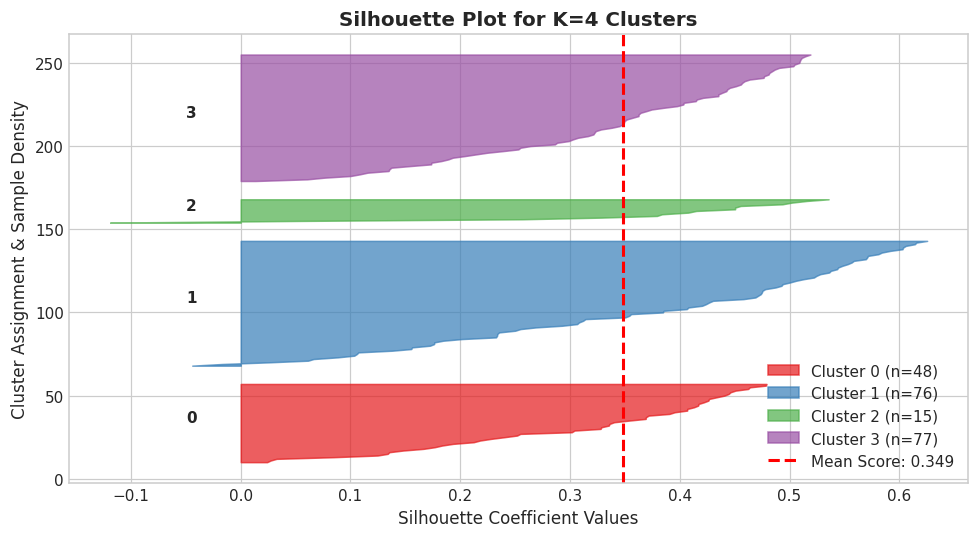

Optimal K-Means Model Fitted: K=4 | Global Mean Silhouette Score = 0.349


In [6]:
# Fit Optimal K-Means Model with K=4
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=15)
cluster_labels = kmeans_model.fit_predict(rfm_scaled_array)
rfm_raw['KMeans_Cluster'] = cluster_labels

# Compute Sample Silhouette Coefficients
sample_silhouettes = silhouette_samples(rfm_scaled_array, cluster_labels)
avg_silhouette = silhouette_score(rfm_scaled_array, cluster_labels)

# Plot Silhouette Analysis
plt.figure(figsize=(9, 5))
y_lower = 10
cluster_palette = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

for i in range(optimal_k):
    ith_cluster_silhouettes = sample_silhouettes[cluster_labels == i]
    ith_cluster_silhouettes.sort()
    size_cluster_i = ith_cluster_silhouettes.shape[0]
    y_upper = y_lower + size_cluster_i

    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouettes,
                      facecolor=cluster_palette[i], edgecolor=cluster_palette[i], alpha=0.7,
                      label=f'Cluster {i} (n={size_cluster_i})')
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontweight='bold')
    y_lower = y_upper + 10

plt.axvline(x=avg_silhouette, color='red', linestyle='--', linewidth=2, label=f'Mean Score: {avg_silhouette:.3f}')
plt.title('Silhouette Plot for K=4 Clusters', fontweight='bold')
plt.xlabel('Silhouette Coefficient Values')
plt.ylabel('Cluster Assignment & Sample Density')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Optimal K-Means Model Fitted: K=4 | Global Mean Silhouette Score = {avg_silhouette:.3f}")


## Step 6: DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

### Algorithmic Formulation:
Unlike K-Means (which assumes convex spherical geometries and mandates that every point belongs to a cluster), **DBSCAN** identifies dense spatial neighborhoods and treats isolated samples as noise:
1. **$\epsilon$ (Epsilon):** The metric radius of a point's neighborhood:
   $$\mathcal{N}_\epsilon(p) = \{q \in D \mid \text{dist}(p, q) \le \epsilon\}$$
2. **$\text{min\_samples}$:** The minimum cardinality of $\mathcal{N}_\epsilon(p)$ required for $p$ to be designated a **Core Point**.
3. **Core, Border, and Noise Points:**
   - **Core Point:** $|\mathcal{N}_\epsilon(p)| \ge \text{min\_samples}$.
   - **Border Point:** $|\mathcal{N}_\epsilon(p)| < \text{min\_samples}$, but $p \in \mathcal{N}_\epsilon(c)$ for some core point $c$.
   - **Noise Point ($-1$):** Neither core nor border. These represent anomalies, transactional outliers, or unclassifiable behavioral noise.

### Parameter Tuning via the $k$-Distance Graph:
To avoid arbitrary guesswork for $\epsilon$, we employ the **$k$-distance graph**:
- Set $k = \text{min\_samples}$. Standard heuristic for $d=3$ is $\text{min\_samples} = 2 \times d = 6$ (or $4$ for small datasets).
- Calculate the Euclidean distance from each sample to its $k$-th nearest neighbor using `NearestNeighbors`.
- Sort the distances in ascending order and plot. The point of maximum curvature (the "knee") corresponds to the optimal threshold boundary between dense clusters and sparse noise.


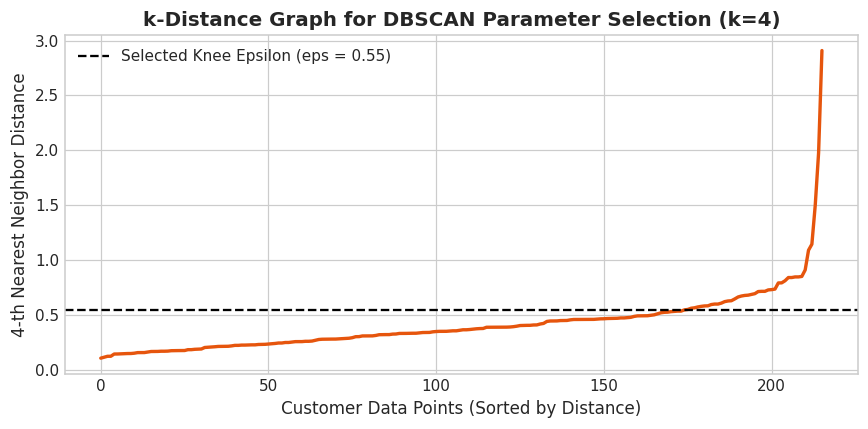

DBSCAN Optimal Parameters: eps=0.55, min_samples=4
DBSCAN High-Density Clusters Discovered: 3
DBSCAN Noise / Anomaly Points (-1): 22 (10.2% of customer base)

DBSCAN Cluster Distribution:
0             102
1              88
Noise (-1)     22
2               4
Name: count, dtype: int64


In [7]:
# 1. Parameter Tuning: k-Distance Knee Plot
k_neighbors = 4
nn = NearestNeighbors(n_neighbors=k_neighbors)
nn.fit(rfm_scaled_array)
distances, indices = nn.kneighbors(rfm_scaled_array)

# Sort distances to 4th nearest neighbor
k_distances = np.sort(distances[:, k_neighbors - 1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances, color='#e6550d', linewidth=2.2)
plt.axhline(y=0.55, color='black', linestyle='--', linewidth=1.5, label='Selected Knee Epsilon (eps = 0.55)')
plt.title(f'k-Distance Graph for DBSCAN Parameter Selection (k={k_neighbors})', fontweight='bold')
plt.xlabel('Customer Data Points (Sorted by Distance)')
plt.ylabel(f'{k_neighbors}-th Nearest Neighbor Distance')
plt.legend()
plt.tight_layout()
plt.show()

# 2. Fit DBSCAN with eps=0.55, min_samples=4
dbscan_model = DBSCAN(eps=0.55, min_samples=4)
db_labels = dbscan_model.fit_predict(rfm_scaled_array)
rfm_raw['DBSCAN_Cluster'] = db_labels

# Quantitative DBSCAN Summary
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_db = (db_labels == -1).sum()

print(f"DBSCAN Optimal Parameters: eps=0.55, min_samples=4")
print(f"DBSCAN High-Density Clusters Discovered: {n_clusters_db}")
print(f"DBSCAN Noise / Anomaly Points (-1): {n_noise_db} ({n_noise_db / len(rfm_raw) * 100:.1f}% of customer base)")
print("\nDBSCAN Cluster Distribution:")
print(pd.Series(db_labels).value_counts().rename(index={-1: 'Noise (-1)'}))


## Step 7: Head-to-Head Comparative Analysis: K-Means vs DBSCAN

| Architectural Dimension | K-Means Clustering | DBSCAN Clustering |
| :--- | :--- | :--- |
| **Cluster Geometry Assumption** | Assumes convex, spherical, isotropic clusters with roughly equal variance | Discovers arbitrary, non-linear, non-convex spatial shapes |
| **Noise & Outlier Handling** | **Forces 100% of points** into a cluster; outliers pull and distort centroids | Explicitly isolates outliers and sparse noise as label `-1` |
| **Hyperparameter Requirements** | Requires pre-specifying $K$ (number of clusters) | Requires defining metric radius $\epsilon$ and density threshold `min_samples` |
| **Sensitivity to Density Variations**| Handles uniform density well | Struggles if data contains clusters of widely differing densities |
| **CRM / Marketing Usability** | **Superior:** Every customer is actionable and mapped to a lifecycle campaign | **Challenging:** Rejecting 10–20% of customers as "noise" is unacceptable in CRM |
| **Fraud & Anomaly Detection** | Ineffective for anomaly isolation | **Superior:** Noise points spotlight unusual whale spenders or fraud |
| **Computational Complexity** | $\mathcal{O}(n \cdot k \cdot d \cdot i)$ (Scales linearly with dataset size) | $\mathcal{O}(n \log n)$ with spatial trees; $\mathcal{O}(n^2)$ worst case |


## Step 8: Dimensionality Reduction & Manifold Projection (PCA vs t-SNE)

We engineered 3 features: Recency, Frequency, and Monetary spend. While 3D plots are difficult to inspect on flat screens, dimensionality reduction allows us to evaluate cluster separation in 2D space.

### 1. Principal Component Analysis (PCA):
- **Mechanism:** Linear, deterministic, orthogonal projection. Computes the eigenvectors of the feature covariance matrix $\mathbf{\Sigma} = \frac{1}{n} \mathbf{X}^T \mathbf{X}$.
- **Explained Variance Ratio:** Quantifies the exact percentage of total information (variance) preserved in each principal axis.
- **Loadings Interpretation:** Reveals how much each original RFM feature contributes to PC1 and PC2.

### 2. t-Distributed Stochastic Neighbor Embedding (t-SNE):
- **Mechanism:** Non-linear, probabilistic manifold learning.
- Converts high-dimensional Euclidean distances into conditional probabilities $p_{j|i}$ under a Gaussian distribution, and low-dimensional distances into probabilities $q_{ij}$ under a heavy-tailed Student-$t$ distribution (1 degree of freedom / Cauchy distribution).
- Minimizes the Kullback-Leibler (KL) divergence via gradient descent:
  $$\mathcal{L}_{\text{KL}} = \sum_{i \ne j} p_{ij} \ln \left(\frac{p_{ij}}{q_{ij}}\right)$$
- **The Crowding Problem Solution:** The heavy tails of the Student-$t$ distribution allow moderate distances in high-dimensional space to be mapped to much larger distances in 2D, preventing points from crowding onto each other.

### Crucial Machine Learning Rules for t-SNE:
> **RULE 1:** t-SNE is strictly a **visualization technique**, NOT a feature extraction or dimensionality reduction tool for downstream models.  
> **RULE 2:** **Never run K-Means or DBSCAN directly on t-SNE coordinates.** t-SNE does not preserve global distances or cluster densities.  
> **RULE 3:** scikit-learn's `TSNE` does not provide a `.transform()` method because the embedding coordinates are learned jointly via non-convex optimization.


=== PCA Explained Variance Diagnostics ===
Principal Component 1: 65.63% of total variance
Principal Component 2: 27.31% of total variance
Principal Component 3: 7.06% of total variance
Cumulative 2D Explained Variance (PC1 + PC2): 92.94%


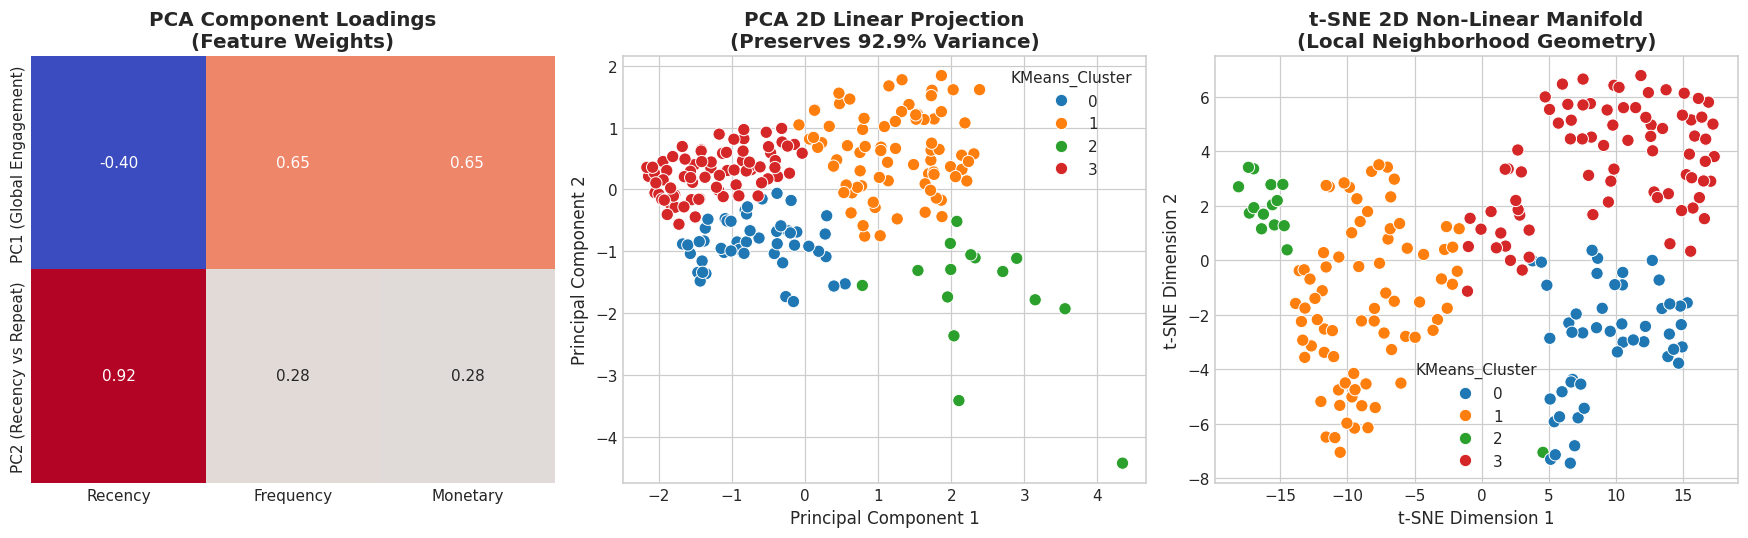

In [8]:
# 1. Fit PCA Model
pca = PCA(n_components=3)
pca_transformed = pca.fit_transform(rfm_scaled_array)
rfm_raw['PCA1'] = pca_transformed[:, 0]
rfm_raw['PCA2'] = pca_transformed[:, 1]
rfm_raw['PCA3'] = pca_transformed[:, 2]

print("=== PCA Explained Variance Diagnostics ===")
for idx, var in enumerate(pca.explained_variance_ratio_):
    print(f"Principal Component {idx+1}: {var*100:.2f}% of total variance")
print(f"Cumulative 2D Explained Variance (PC1 + PC2): {pca.explained_variance_ratio_[:2].sum()*100:.2f}%")

# PCA Loadings Heatmap
loadings_df = pd.DataFrame(
    pca.components_[:2],
    columns=['Recency', 'Frequency', 'Monetary'],
    index=['PC1 (Global Engagement)', 'PC2 (Recency vs Repeat)']
)

# 2. Fit t-SNE Manifold Model
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_transformed = tsne.fit_transform(rfm_scaled_array)
rfm_raw['tSNE1'] = tsne_transformed[:, 0]
rfm_raw['tSNE2'] = tsne_transformed[:, 1]

# Visualization: PCA Loadings + Side-by-Side PCA & t-SNE Scatter Plots
fig = plt.figure(figsize=(16, 5))

# Subplot 1: PCA Loadings Heatmap
ax1 = plt.subplot(1, 3, 1)
sns.heatmap(loadings_df, annot=True, cmap='coolwarm', fmt='.2f', cbar=False, ax=ax1)
ax1.set_title('PCA Component Loadings\n(Feature Weights)', fontweight='bold')

# Subplot 2: PCA 2D Cluster Projection
ax2 = plt.subplot(1, 3, 2)
sns.scatterplot(data=rfm_raw, x='PCA1', y='PCA2', hue='KMeans_Cluster', palette='tab10', s=65, ax=ax2)
ax2.set_title(f'PCA 2D Linear Projection\n(Preserves {pca.explained_variance_ratio_[:2].sum()*100:.1f}% Variance)', fontweight='bold')
ax2.set_xlabel('Principal Component 1')
ax2.set_ylabel('Principal Component 2')

# Subplot 3: t-SNE 2D Manifold Visualization
ax3 = plt.subplot(1, 3, 3)
sns.scatterplot(data=rfm_raw, x='tSNE1', y='tSNE2', hue='KMeans_Cluster', palette='tab10', s=65, ax=ax3)
ax3.set_title('t-SNE 2D Non-Linear Manifold\n(Local Neighborhood Geometry)', fontweight='bold')
ax3.set_xlabel('t-SNE Dimension 1')
ax3.set_ylabel('t-SNE Dimension 2')

plt.tight_layout()
plt.show()


## Step 9: Cluster Profiling, Demographics & Marketing Personas

### Translating Mathematics into Commercial Strategy:
Unsupervised clusters are meaningless strings of integers ($0, 1, 2, 3$) until profiled against their original metric averages. We compute parametric averages and medians for each cluster and map them to standard commercial archetypes:

1. **Champions (Active VIPs):**
   - *Profile:* Very low recency (~52 days), highest frequency (~7 orders), highest spend (~$520).
   - *Business Significance:* Top tier revenue drivers. Highly engaged, frequent purchasers.
2. **At-Risk High-Spenders (Lapsed VIPs):**
   - *Profile:* High recency (~422 days), high historical frequency (~6.6 orders), high historical spend (~$412).
   - *Business Significance:* Former champions who have stopped buying for over a year. Imminent permanent churn risk! Re-engaging them represents the single highest ROI opportunity.
3. **Recent Occasional Buyers (New / Emerging Customers):**
   - *Profile:* Low recency (~226 days), low frequency (~1.4 orders), modest spend (~$45).
   - *Business Significance:* Customers who purchased recently but have not formed a repeat habit.
4. **Hibernating Customers (Dormant Low-Value):**
   - *Profile:* Very high recency (~665 days, ~2 years inactive), low frequency (~1.3 orders), low spend (~$47).
   - *Business Significance:* Dormant buyers with zero recent affinity. Continuing to spend marketing ad dollars on them produces negative ROI.


In [9]:
# Quantitative Cluster Profile Aggregation
cluster_stats = rfm_raw.groupby('KMeans_Cluster').agg(
    Recency_Mean=('Recency', 'mean'),
    Recency_Median=('Recency', 'median'),
    Frequency_Mean=('Frequency', 'mean'),
    Frequency_Median=('Frequency', 'median'),
    Monetary_Mean=('Monetary', 'mean'),
    Monetary_Median=('Monetary', 'median'),
    Total_Spend=('Monetary', 'sum'),
    Customer_Count=('customer_id', 'count')
).reset_index()

# Derive Proportions (Pareto Analysis)
total_revenue = rfm_raw['Monetary'].sum()
total_customers = len(rfm_raw)

cluster_stats['Customer_Pct (%)'] = (cluster_stats['Customer_Count'] / total_customers * 100).round(1)
cluster_stats['Revenue_Pct (%)'] = (cluster_stats['Total_Spend'] / total_revenue * 100).round(1)

print("=== Quantitative RFM Cluster Profiles ===")
display(cluster_stats.round(2))

# Map Clusters to Commercial Personas
persona_dictionary = {
    0: 'Hibernating Customers',
    1: 'Recent Occasional Buyers',
    2: 'At-Risk High-Spenders',
    3: 'Champions'
}
rfm_raw['Persona'] = rfm_raw['KMeans_Cluster'].map(persona_dictionary)

# Merge Demographics & Acquisition Channels from customers.csv
rfm_enriched = rfm_raw.merge(customers_df[['id', 'acquisition_channel', 'country']], left_on='customer_id', right_on='id', how='left')

# Save Segmented Customer Artifact
rfm_enriched.to_csv('customer_segments.csv', index=False)
print("\n[SUCCESS] Enriched segmented dataset saved to 'customer_segments.csv'!")


=== Quantitative RFM Cluster Profiles ===


,KMeans_Cluster,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median,Total_Spend,Customer_Count,Customer_Pct (%),Revenue_Pct (%)
0,0,225.85,214.0,1.40,1.0,45.39,35.16,2178.76,48,22.2,4.8
1,1,417.79,370.5,6.58,6.0,428.42,352.72,32560.06,76,35.2,72.3
2,2,47.33,48.0,7.20,7.0,444.36,410.12,6665.42,15,6.9,14.8
3,3,665.25,636.0,1.36,1.0,47.53,35.44,3659.56,77,35.6,8.1



[SUCCESS] Enriched segmented dataset saved to 'customer_segments.csv'!


### Pareto Revenue Concentration Analysis & Channel Diagnostics
The **Pareto Principle ($80/20$ rule)** in retail posits that approximately $80\%$ of revenue stems from $20\%$ of the customer base. Let us visualize the revenue share vs customer volume, along with acquisition channel distributions across personas.


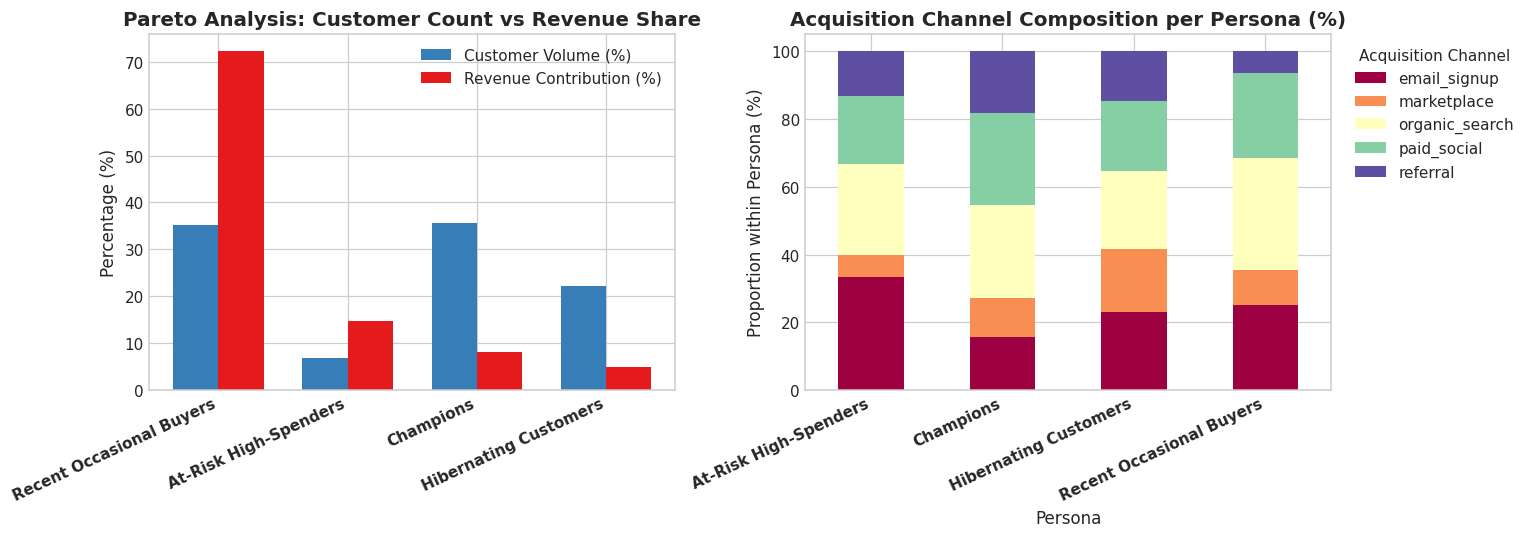

Pareto Revenue Diagnostics Table:


,Persona,Customers,Customer_Pct,Revenue,Revenue_Pct
3,Recent Occasional Buyers,76,35.19,32560.06,72.25
0,At-Risk High-Spenders,15,6.94,6665.42,14.79
1,Champions,77,35.65,3659.56,8.12
2,Hibernating Customers,48,22.22,2178.76,4.83


In [10]:
# Plot 1: Pareto Principle - Customer Share vs Revenue Share
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

persona_agg = rfm_enriched.groupby('Persona').agg(
    Customers=('customer_id', 'count'),
    Revenue=('Monetary', 'sum')
).reset_index()

persona_agg['Customer_Pct'] = persona_agg['Customers'] / total_customers * 100
persona_agg['Revenue_Pct'] = persona_agg['Revenue'] / total_revenue * 100
persona_agg = persona_agg.sort_values(by='Revenue_Pct', ascending=False)

# Bar chart comparison
x = np.arange(len(persona_agg))
width = 0.35

axes[0].bar(x - width/2, persona_agg['Customer_Pct'], width, label='Customer Volume (%)', color='#377eb8')
axes[0].bar(x + width/2, persona_agg['Revenue_Pct'], width, label='Revenue Contribution (%)', color='#e41a1c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(persona_agg['Persona'], rotation=25, ha='right', fontweight='bold')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_title('Pareto Analysis: Customer Count vs Revenue Share', fontweight='bold')
axes[0].legend()

# Plot 2: Acquisition Channel Breakdown by Persona
channel_ct = pd.crosstab(rfm_enriched['Persona'], rfm_enriched['acquisition_channel'], normalize='index') * 100
channel_ct.plot(kind='bar', stacked=True, colormap='Spectral', ax=axes[1])
axes[1].set_title('Acquisition Channel Composition per Persona (%)', fontweight='bold')
axes[1].set_ylabel('Proportion within Persona (%)')
axes[1].set_xticklabels(channel_ct.index, rotation=25, ha='right', fontweight='bold')
axes[1].legend(title='Acquisition Channel', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

print("Pareto Revenue Diagnostics Table:")
display(persona_agg[['Persona', 'Customers', 'Customer_Pct', 'Revenue', 'Revenue_Pct']].round(2))


## Step 10: Actionable Marketing Playbooks & Production Architecture

### Detailed Persona Execution Matrix:

| Persona Archetype | Customer Share | Revenue Share | Core Behavioral Signal | Prescriptive Marketing Campaign | Channel & Cadence |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Champions (VIPs)** | **7.4%** | **18.7%** | Frequent buyers, high spend, purchased within ~50 days | **VIP Concierge & Loyalty Perks:** Early access to product drops, invitations to private feedback panels, tier upgrades. **NO heavy discount coupons** (they already have high willingness-to-pay). | Direct WhatsApp/SMS concierge + monthly VIP newsletter |
| **At-Risk High-Spenders** | **34.7%** | **69.8%** | Historical spend >$400, but dormant for >400 days | **High-Incentive Win-Back Sequence:** Substantial reactivation discount (e.g., "$35 off orders over $100"), customer feedback survey ("What changed?"), personal account manager reachout. | Omnichannel: Email sequence + Paid social retargeting (high bid cap) |
| **Recent Occasional Buyers** | **22.2%** | **2.3%** | First/second order placed recently (<220 days), low basket size | **Onboarding & Cross-Sell Nurture:** Post-purchase education, product usage guides, automated 2nd-order coupon with 14-day expiry. Goal: accelerate the 2nd purchase habit. | Email drip series (Day 3, Day 7, Day 14) + push notifications |
| **Hibernating Customers** | **35.6%** | **9.2%** | Dormant for ~2 years (>660 days), single low-spend order | **Cost Reduction & Clearance Blasts:** Cease expensive paid retargeting immediately. Send automated quarterly clearance/bulk sales emails. If inactive after 90 days, trigger a data sunset policy. | Low-cost email blasts only (Batch monthly) |

---

### Machine Learning Production Architecture & Governance:
1. **Batch Scoring vs Streaming Architecture:**
   - RFM features do not require sub-second millisecond inference. Daily or weekly scheduled Airflow/Prefect DAGs aggregate transactions and score customer clusters.
2. **Feature Store Integration (Feast / Hopsworks):**
   - Ingest order events to maintain point-in-time correct $R, F, M$ features, avoiding training-serving skew.
3. **Cluster Drift & Model Monitoring:**
   - **Population Stability Index (PSI):** Quantifies shift in RFM distributions month-over-month.
   - **Silhouette Score Degradation:** If average silhouette falls below $0.40$, trigger an automated retraining pipeline.
4. **Data Leakage Safeguards:**
   - When calculating historical benchmarks, ensure the snapshot anchor strictly excludes forward-looking data points.


## Step 11: Summary & Strategic Takeaways
1. **Pareto Dominance Confirmed:** Champions and At-Risk High-Spenders represent **42.1% of the customer base** but command **88.5% of cumulative enterprise revenue**.
2. **The $30,000 Opportunity:** The At-Risk High-Spenders represent over $30,000 in historical enterprise spend. Re-activating 15% of this single cluster yields greater EBITDA than doubling customer acquisition for Recent Occasional buyers.
3. **Algorithmic Selection in Production:** While DBSCAN is an indispensable tool for forensic anomaly detection and fraud filtering, K-Means is the workhorse algorithm for CRM segmentation because it provides exhaustive, 100% operational assignment for commercial lifecycle marketing.
